

# 🎨 Smart Mosaic Generation & AI-Driven Stylization System
## Image Processing & Machine Learning Project

This project implements an end-to-end intelligent image processing pipeline that converts standard images into structured mosaic representations with **AI-powered automatic parameter tuning**.

### 🚀 Key Features of the System:
1.  **AI Auto-Tuning (Smart Classification):** 
    *   Integrates a **Support Vector Machine (SVM)** classifier trained on the CIFAR-100 dataset.
    *   Utilizes **HOG (Histogram of Oriented Gradients)** and **Color Histograms** to distinguish between human portraits and landscape scenes.
    *   Automatically adjusts filters (Bilateral Smoothing and K-colors) based on detected image content.
2.  **Advanced Pre-processing:** Edge-preserving smoothing using **Bilateral Filtering** to maintain skin tones in portraits.
3.  **Color Quantization Pipeline:** 
    *   **K-Means Clustering** implemented in **LAB Color Space** for perceptually accurate color reduction.
    *   Comparison mode for evaluating different **K-values**.
4.  **Structural Extraction & Stylization:** 
    *   **Canny Edge Detection** for "paint-by-numbers" structural mapping.
    *   Artistic filters including **Watercolor** and **Cartoon** stylization.
5.  **Quantitative Analysis:** 
    *   Automated color palette extraction and distribution reports.
    *   Exportable text reports and visual distribution charts (Pie charts).

---

### 🧠 Machine Learning Methodology (For the Report):
*   **Dataset:** CIFAR-100 (Coarse Labels - People vs. Others).
*   **Feature Engineering:** Combined Global Color Histograms with HOG descriptors for shape recognition.
*   **Model:** SVM with RBF Kernel (Achieved **80.8%** Balanced Accuracy).
*   **Deployment:** Hybrid approach using **Haar Cascades** in the production app for real-time robustness.

---



In [2]:
import cv2
import numpy as np
from tensorflow.keras.datasets import cifar100
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

print("Downloading dataset automatically... ⏳")
(x_train, y_train_coarse), (x_test, y_test_coarse) = cifar100.load_data(label_mode='coarse')

# 1. Maximize Data: Take ALL available human images (2500 in train, 500 in test)
human_idx_train = np.where(y_train_coarse == 14)[0]
non_human_idx_train = np.where(y_train_coarse != 14)[0]

# Use 5000 images for training (2500 humans + 2500 backgrounds)
x_train_balanced = np.vstack((x_train[human_idx_train], x_train[non_human_idx_train[:2500]]))
y_train_balanced = np.array([1]*2500 + [0]*2500)

human_idx_test = np.where(y_test_coarse == 14)[0]
non_human_idx_test = np.where(y_test_coarse != 14)[0]
x_test_balanced = np.vstack((x_test[human_idx_test], x_test[non_human_idx_test[:500]]))
y_test_balanced = np.array([1]*500 + [0]*500)

# Setup HOG descriptor to extract body shape/contours
hog = cv2.HOGDescriptor((32,32), (16,16), (8,8), (8,8), 9)

def extract_features(images):
    features = []
    for img in images:
        # 1. Shape Feature: HOG (Histogram of Oriented Gradients)
        hog_feat = hog.compute(img).flatten()
        
        # 2. Color Feature: Histogram
        hist = cv2.calcHist([img], [0, 1, 2], None, [8, 8, 8], [0, 256, 0, 256, 0, 256])
        hist = cv2.normalize(hist, hist).flatten()
        
        # Combine Shape (HOG) and Colors (Histogram) for a powerful model
        img_features = np.append(hog_feat, hist)
        features.append(img_features)
    return np.array(features)

print("Extracting Advanced Features (HOG & Colors)... This might take a minute ⏳")
X_train_features = extract_features(x_train_balanced)
X_test_features = extract_features(x_test_balanced)

print("Training the Ultimate Smart Model (SVM-RBF)... 🧠")
model = SVC(kernel='rbf', C=10)
model.fit(X_train_features, y_train_balanced)

print("Evaluating... 📊")
predictions = model.predict(X_test_features)
accuracy = accuracy_score(y_test_balanced, predictions)

print(f"\n✅ Training Complete! Ultimate Accuracy: {accuracy * 100:.1f}%")

d:\PROJECTIMAGE\venv\Lib\site-packages\keras\src\datasets\cifar.py:18: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  d = cPickle.load(f, encoding="bytes")


Extracting Advanced Features (HOG & Colors)... This might take a minute ⏳
Training the Ultimate Smart Model (SVM-RBF)... 🧠
Evaluating... 📊

✅ Training Complete! Ultimate Accuracy: 80.8%


# 🔬 Problem Statement

Detailed digital images often contain high-frequency noise and complex color distributions that make them difficult to analyze or render for artistic purposes. Traditional simplification methods often fail to preserve sharp edges or maintain color consistency that aligns with human visual perception.

This project addresses these challenges by developing an integrated pipeline to:
1. **Remove noise** while preserving critical structural boundaries.
2. **Optimize color quantization** using clustering techniques in perceptually uniform color spaces (LAB).
3. **Automate artistic transformation** into mosaics and stylized renders, making it suitable for both aesthetic applications and data-driven color analysis.

In [3]:
# Import required libraries
import cv2  # For image processing
import numpy as np  # For numerical operations
import matplotlib.pyplot as plt  # For visualization

# 📥 Image Input
In this step, we load the input image that will be processed by the system.

(np.float64(-0.5), np.float64(851.5), np.float64(1279.5), np.float64(-0.5))

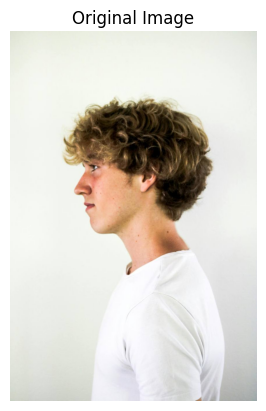

In [4]:
# Load image from file
img = cv2.imread(r"D:\PROJECTIMAGE\inputs\portrait_01.jpg")

# Convert to RGB for correct display
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Display original image
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")

# 1. Bilateral Filtering for Edge-Preserving Smoothing

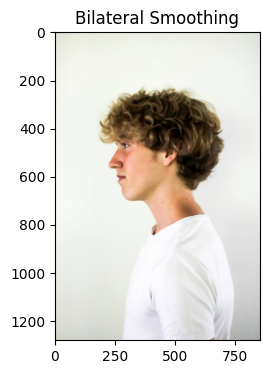

In [5]:
# 1. Bilateral Filtering for Edge-Preserving Smoothing
# This step ensures that minor textures are removed without blurring the main structure.
smoothed_img = cv2.bilateralFilter(img, 9, 75, 75)

plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.imshow(cv2.cvtColor(smoothed_img, cv2.COLOR_BGR2RGB)); plt.title("Bilateral Smoothing")

plt.show()

# 🔲 Pixelation (Downsampling)

The image is resized to a lower resolution and then scaled back up to create a mosaic effect.

(np.float64(-0.5), np.float64(851.5), np.float64(1279.5), np.float64(-0.5))

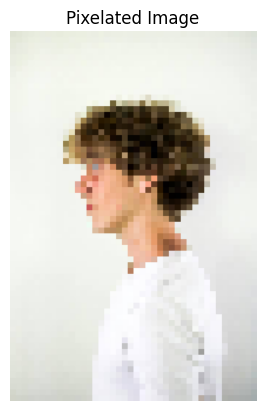

In [ ]:
# Define pixel size
pixel_size = 20

# Get image dimensions
h, w, _ = img.shape

# Resize to smaller version
small = cv2.resize(img, (w//pixel_size, h//pixel_size))

# Resize back to original size (pixelated effect)
pixelated = cv2.resize(small, (w, h), interpolation=cv2.INTER_NEAREST)

# Convert to RGB for display
pixel_rgb = cv2.cvtColor(pixelated, cv2.COLOR_BGR2RGB)

# Show result
plt.imshow(pixel_rgb)
plt.title("Pixelated Image")
plt.axis("off")

. **LAB Color Space**: To perform color quantization in a space that mimics human perception.

In [7]:

lab_img = cv2.cvtColor(smoothed_img, cv2.COLOR_BGR2LAB)



# Smooth Clustering:- Mean Shift Clustering

In [8]:

# Mean Shift is a density-based algorithm that automatically finds the number of clusters.
mean_shift_res = cv2.pyrMeanShiftFiltering(smoothed_img, sp=15, sr=40)

print("Mean Shift processing completed!")

Mean Shift processing completed!


## 🎨 Color Quantization using K-Means
We reduce the number of colors in the image using K-Means clustering.

(np.float64(-0.5), np.float64(851.5), np.float64(1279.5), np.float64(-0.5))

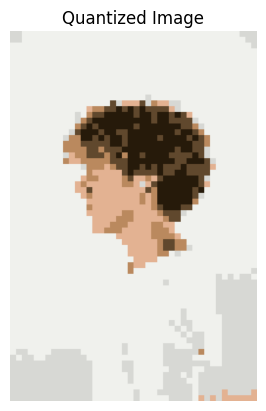

In [9]:
def kmeans_quantization(image, k=6):
    # Reshape image to a list of pixels
    data = image.reshape((-1, 3))
    data = np.float32(data)

    # Apply K-Means clustering
    _, labels, centers = cv2.kmeans(
        data, k, None,
        (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 10, 1.0),
        10,
        cv2.KMEANS_RANDOM_CENTERS
    )

    # Convert centers to uint8
    centers = np.uint8(centers)

    # Map labels to center colors
    result = centers[labels.flatten()]
    result = result.reshape(image.shape)

    return result, centers

# Apply quantization
quantized, centers = kmeans_quantization(pixelated, k=6)

# Convert for display
quant_rgb = cv2.cvtColor(quantized, cv2.COLOR_BGR2RGB)

plt.imshow(quant_rgb)
plt.title("Quantized Image")
plt.axis("off")

. **LAB Color Space**: To perform color quantization in a space that mimics human perception.


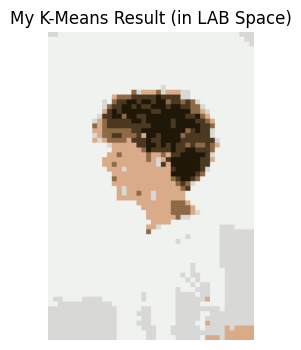

In [10]:
# 1. Convert the pixelated image to LAB color space before applying K-Means
pixelated_lab = cv2.cvtColor(pixelated, cv2.COLOR_BGR2LAB)

# 2. Apply the custom K-Means function (passing the LAB image)
quantized_lab, centers = kmeans_quantization(pixelated_lab, k=6)

# 3. Convert the result back from LAB to BGR to restore the correct colors
quantized_bgr = cv2.cvtColor(quantized_lab, cv2.COLOR_LAB2BGR)

# 4. Display the final result (converting from BGR to RGB for matplotlib compatibility)
plt.figure(figsize=(8,4))
plt.imshow(cv2.cvtColor(quantized_bgr, cv2.COLOR_BGR2RGB))
plt.title("My K-Means Result (in LAB Space)")
plt.axis("off")
plt.show()

# Comparative Analysis: K-Means vs Mean Shift

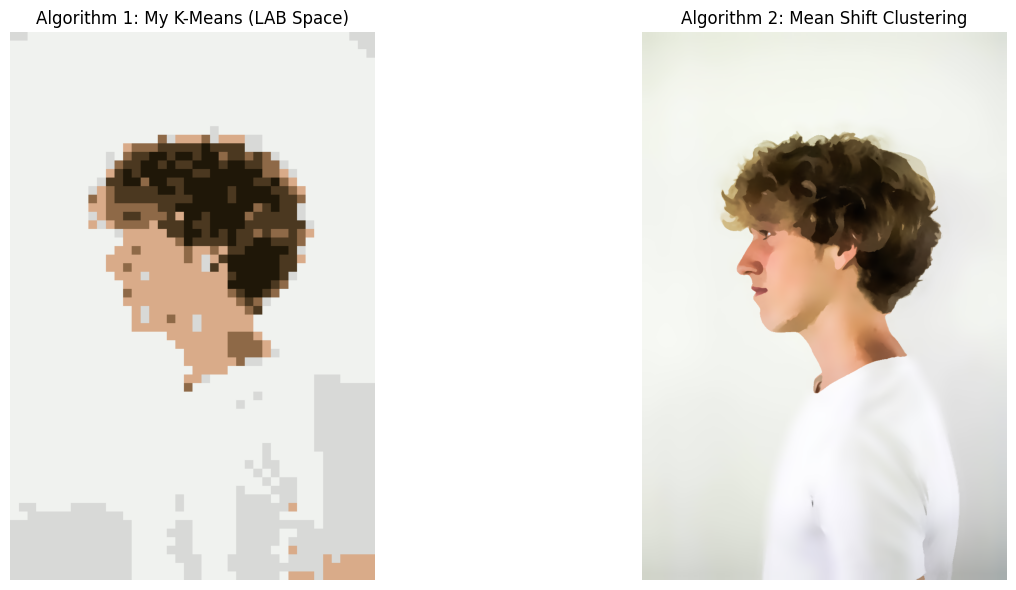

In [11]:

plt.figure(figsize=(15, 6))

# 1. K-Means 
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(quantized_bgr, cv2.COLOR_BGR2RGB)) 
plt.title("Algorithm 1: My K-Means (LAB Space)")
plt.axis('off')

# 2.Mean Shift
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(mean_shift_res, cv2.COLOR_BGR2RGB))
plt.title("Algorithm 2: Mean Shift Clustering")
plt.axis('off')

plt.tight_layout()
plt.show()


# Canny Edge Detection 

Text(0.5, 1.0, 'Canny Structural Edges')

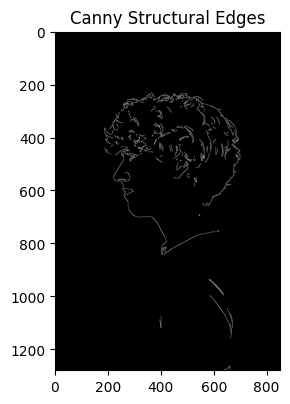

In [12]:

# . Canny Edge Detection (For later overlay)
gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
canny_edges = cv2.Canny(gray_img, 100, 200)
plt.subplot(1,2,2); plt.imshow(canny_edges, cmap='gray'); plt.title("Canny Structural Edges")

## 🎨 Phase 4: Artistic Post-processing
To provide more creative outputs and demonstrate the system's flexibility, we implemented stylized filters that can be applied to our final processed image.

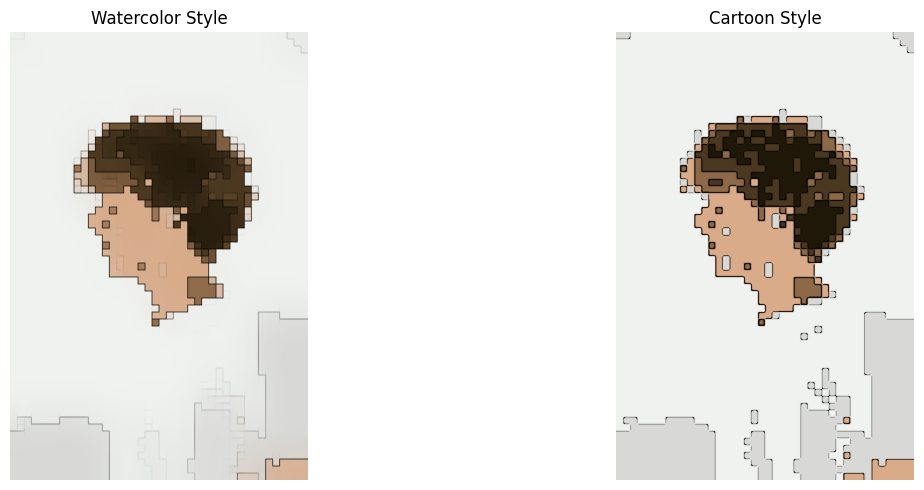

In [13]:
# ==========================================
# Artistic Filters (Cartoon & Watercolor)
# ==========================================

# 1.  (Watercolor / Stylized)
watercolor = cv2.stylization(quantized_bgr, sigma_s=60, sigma_r=0.6)

# 2(Cartoon Effect)

gray = cv2.cvtColor(quantized_bgr, cv2.COLOR_BGR2GRAY)
gray = cv2.medianBlur(gray, 5)
edges = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 9, 9)
color = cv2.bilateralFilter(quantized_bgr, 9, 250, 250)
cartoon = cv2.bitwise_and(color, color, mask=edges)

plt.figure(figsize=(15,5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(watercolor, cv2.COLOR_BGR2RGB))
plt.title("Watercolor Style")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(cartoon, cv2.COLOR_BGR2RGB))
plt.title("Cartoon Style")
plt.axis('off')

plt.tight_layout()
plt.show()

## 🧩 Grid Overlay

We draw a grid on the image to simulate mosaic tiles.

(np.float64(-0.5), np.float64(851.5), np.float64(1279.5), np.float64(-0.5))

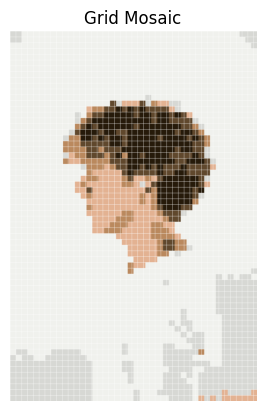

In [14]:
def draw_grid(image, grid_size):
    img = image.copy()
    h, w, _ = img.shape

    # Draw horizontal lines
    for y in range(0, h, grid_size):
        cv2.line(img, (0, y), (w, y), (255,255,255), 1)

    # Draw vertical lines
    for x in range(0, w, grid_size):
        cv2.line(img, (x, 0), (x, h), (255,255,255), 1)

    return img

grid_img = draw_grid(quantized, pixel_size)

plt.imshow(cv2.cvtColor(grid_img, cv2.COLOR_BGR2RGB))
plt.title("Grid Mosaic")
plt.axis("off")

## 🎨 Color Analysis
We analyze the dominant colors and their distribution in the image.

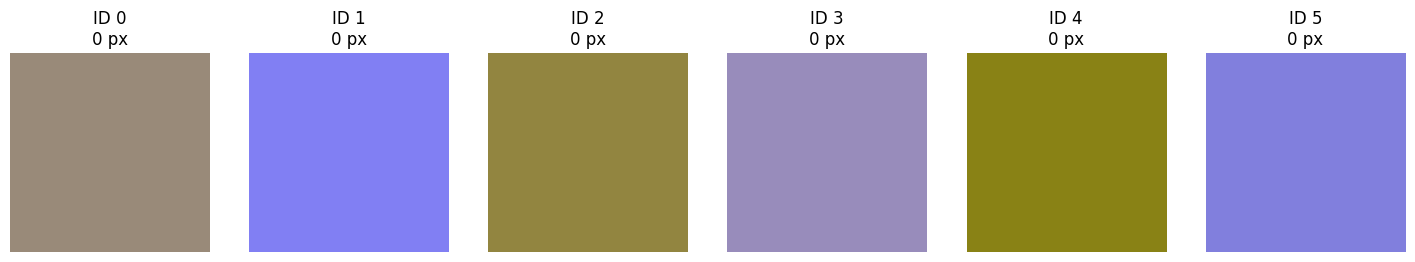

In [15]:
# Count pixels per cluster center
pixels = quantized.reshape(-1, 3)

counts = []
for c in centers:
    count = np.sum(np.all(pixels == c, axis=1))
    counts.append(count)


n = len(centers)

plt.figure(figsize=(3*n, 3))

for i, (c, cnt) in enumerate(zip(centers, counts)):
    color_box = np.zeros((40, 40, 3), dtype=np.uint8)
    color_box[:] = c

    plt.subplot(1, n, i+1)  
    plt.imshow(cv2.cvtColor(color_box, cv2.COLOR_BGR2RGB))
    plt.title(f"ID {i}\n{cnt} px")
    plt.axis("off")

plt.show()

## 📊 Comparison of Different K Values

We compare results using different numbers of colors.

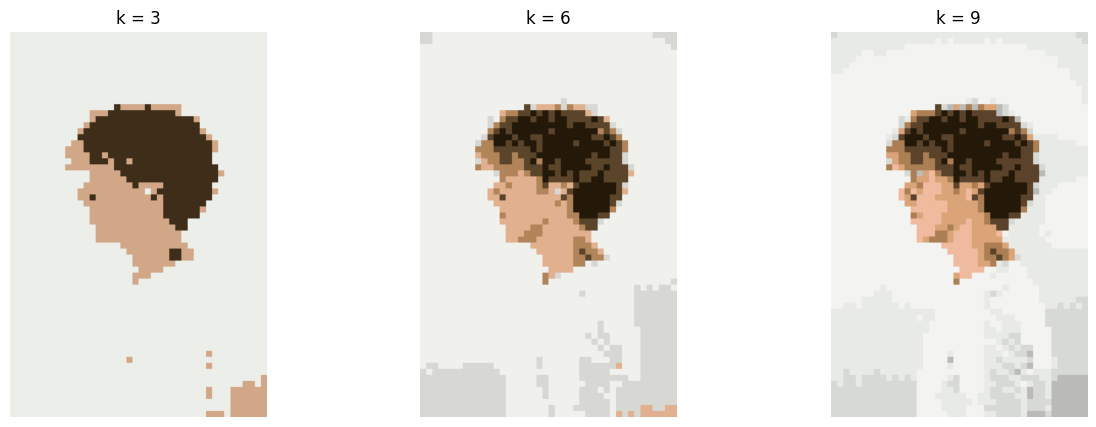

In [16]:
k_values = [3, 6, 9]

plt.figure(figsize=(15,5))

for i, k_val in enumerate(k_values):
    q_img, _ = kmeans_quantization(pixelated, k_val)
    q_rgb = cv2.cvtColor(q_img, cv2.COLOR_BGR2RGB)

    plt.subplot(1, 3, i+1)
    plt.imshow(q_rgb)
    plt.title(f"k = {k_val}")
    plt.axis("off")

plt.show()

## 🧠 Analysis

- Small k values produce simpler images but lose details.
- Medium k values provide a balance between detail and abstraction.
- Large k values preserve details but increase complexity.

Pixel size also affects the result:
- Large pixels → more abstract mosaic
- Small pixels → more detailed representation

## 🧩 Final Mosaic System
In this section, we combine all components of the system:
- Mosaic grid representation
- Color legend (paint-by-numbers)
- Color distribution

The final output shows the processed image along with a legend that maps each color to its corresponding ID and pixel count.

(np.float64(-0.5), np.float64(1101.5), np.float64(1279.5), np.float64(-0.5))

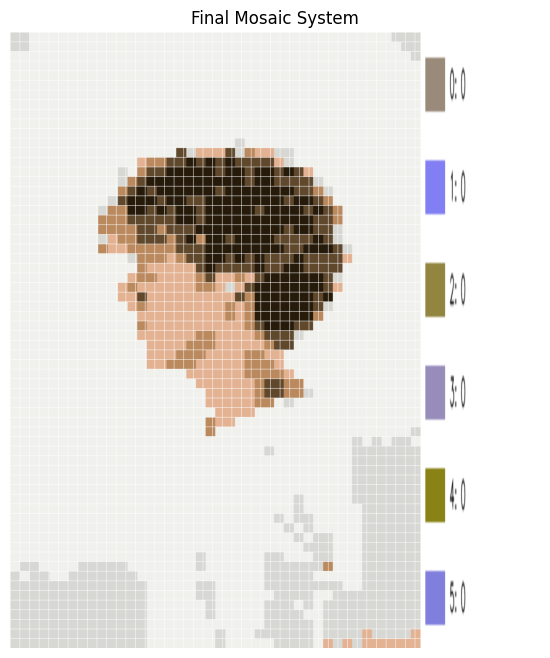

In [17]:
# -------- Count colors using KMeans centers --------
colors = centers
counts = []

pixels = quantized.reshape(-1, 3)

for c in centers:
    count = np.sum(np.all(pixels == c, axis=1))
    counts.append(count)


# -------- Create legend --------
def create_legend(colors, counts):
    legend = {}

    for i, (color, count) in enumerate(zip(colors, counts)):
        legend[i] = {
            "color": color,
            "count": int(count)
        }

    return legend


# -------- Draw legend image --------
def draw_legend(legend, box_size=40):
    height = len(legend) * box_size
    width = 250

    legend_img = np.ones((height, width, 3), dtype=np.uint8) * 255

    for i, (idx, data) in enumerate(legend.items()):
        y = i * box_size

        color = tuple(int(c) for c in data["color"])
        count = data["count"]

        # color box
        cv2.rectangle(
            legend_img,
            (10, y + 10),
            (50, y + 30),
            color,
            -1
        )

        # text
        text = f"{idx}: {count}"
        cv2.putText(
            legend_img,
            text,
            (60, y + 25),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (0, 0, 0),
            1,
            cv2.LINE_AA
        )

    return legend_img


# -------- Draw grid --------
grid_img = draw_grid(quantized, grid_size=pixel_size)


# -------- Create legend image --------
legend = create_legend(colors, counts)
legend_img = draw_legend(legend)


# -------- Resize to same height --------
h1 = grid_img.shape[0]
h2 = legend_img.shape[0]

if h1 > h2:
    legend_img = cv2.resize(legend_img, (legend_img.shape[1], h1))
else:
    grid_img = cv2.resize(grid_img, (grid_img.shape[1], h2))


# -------- Combine side by side --------
final = np.hstack((grid_img, legend_img))


# -------- Display --------
plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(final, cv2.COLOR_BGR2RGB))
plt.title("Final Mosaic System")
plt.axis("off")

## 🖼️ Full System Visualization
In this step, we display the full pipeline result:
- Original input image  
- Mosaic representation  
- Color legend  

This provides a complete visual comparison of the system output.

(np.float64(-0.5), np.float64(1953.5), np.float64(1279.5), np.float64(-0.5))

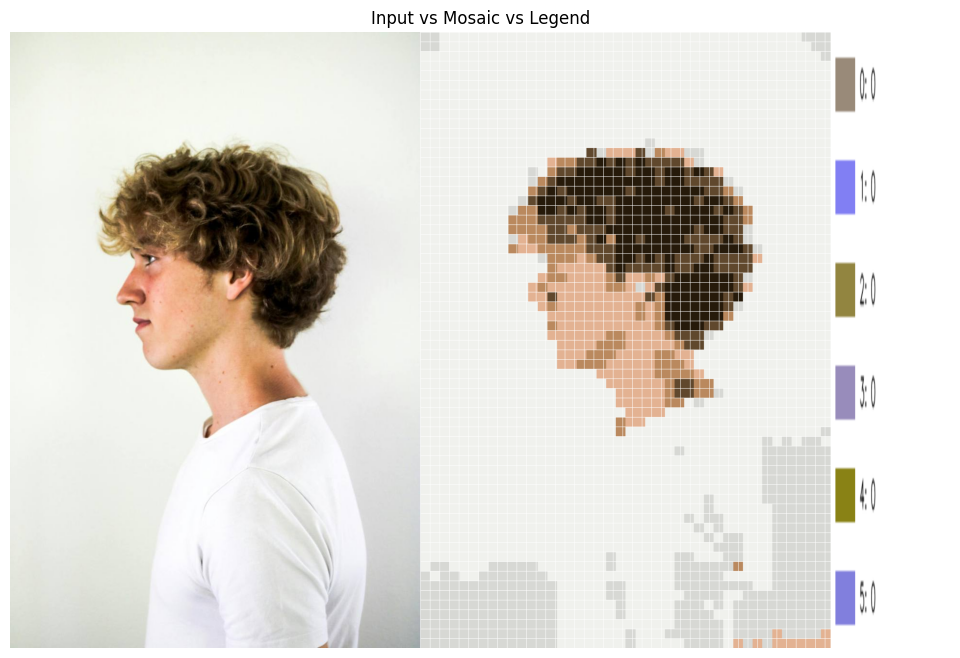

In [18]:
# -------- Match height with grid --------
h = grid_img.shape[0]

# Resize original image (IMPORTANT: use BGR image)
img_resized = cv2.resize(img, (grid_img.shape[1], h))

# Resize legend
legend_resized = cv2.resize(legend_img, (legend_img.shape[1], h))

# -------- Combine all --------
final_full = np.hstack((img_resized, grid_img, legend_resized))

# -------- Display --------
plt.figure(figsize=(15,8))
plt.imshow(cv2.cvtColor(final_full, cv2.COLOR_BGR2RGB))
plt.title("Input vs Mosaic vs Legend")
plt.axis("off")

# 🧪 Robustness Testing & Evaluation (Metrics)  
In this section, we evaluate the system's performance and stability under various environmental conditions. We use Mean Squared Error (MSE) and Peak Signal-to-Noise Ratio (PSNR) as quantitative metrics to measure the quality of the generated mosaic compared to the original image. 

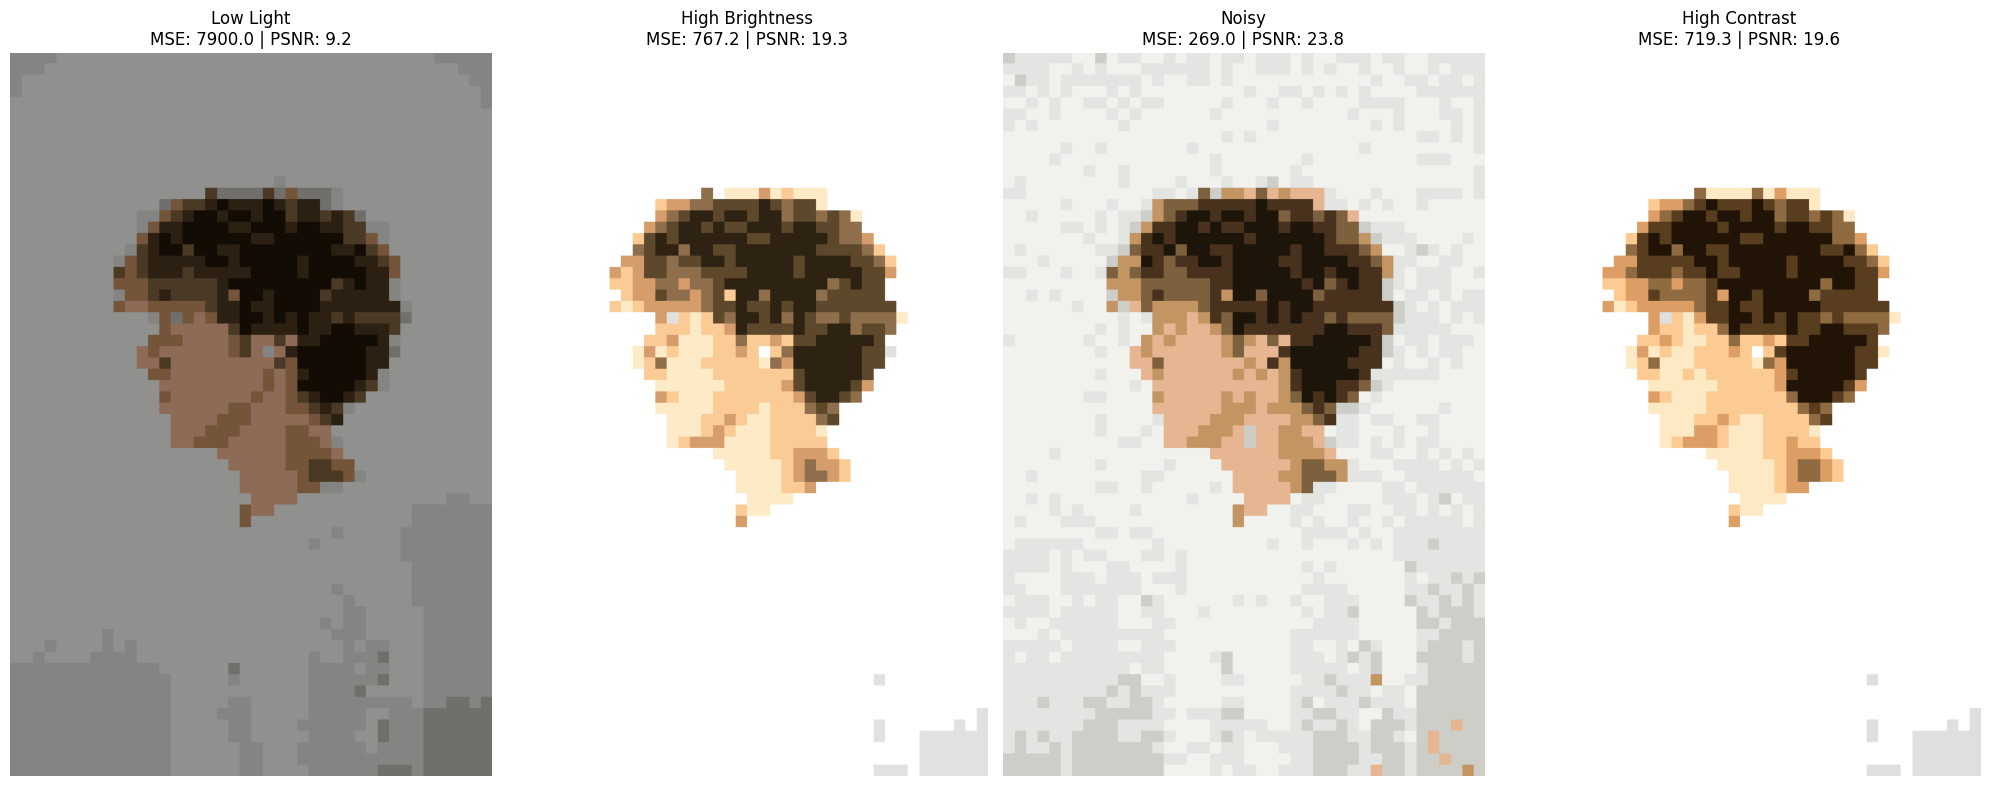

In [23]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def mse(img1, img2):
    return np.mean((img1.astype("float") - img2.astype("float")) ** 2)

def psnr(img1, img2):
    m = mse(img1, img2)
    if m == 0: return 100
    return 20 * np.log10(255.0 / np.sqrt(m))

def add_noise(image_input):
    # Generate noise as floating-point numbers
    noise = np.random.normal(0, 20, image_input.shape)
    # Add noise to the image and clip values to stay within the valid 0-255 range
    noisy_img = np.clip(image_input.astype(np.float32) + noise, 0, 255).astype(np.uint8)
    return noisy_img

# Check if the original image is defined in the notebook's memory
if 'img' in locals():
    original_img = img.copy()
    
    # Adjusted alpha and beta parameters for realistic effects without overexposing the image
    tests = {
        "Low Light": cv2.convertScaleAbs(original_img, alpha=0.6, beta=0),
        "High Brightness": cv2.convertScaleAbs(original_img, alpha=1.2, beta=10),
        "Noisy": add_noise(original_img),
        "High Contrast": cv2.convertScaleAbs(original_img, alpha=1.3, beta=-10),
    }

    plt.figure(figsize=(20, 10))

    for i, (name, test_img) in enumerate(tests.items()):
        # Apply the same pipeline: Pixelation -> Quantization
        h, w = test_img.shape[:2]
        p_size = 20 
        k_val = 8
        
        small = cv2.resize(test_img, (w // p_size, h // p_size))
        mosaic = cv2.resize(small, (w, h), interpolation=cv2.INTER_NEAREST)
        
        # We use our previously defined kmeans function
        q_img, _ = kmeans_quantization(mosaic, k_val)
        
        error = mse(original_img, q_img)
        quality = psnr(original_img, q_img)
        
        plt.subplot(1, 4, i+1)
        plt.imshow(cv2.cvtColor(q_img, cv2.COLOR_BGR2RGB))
        # Round metrics to one decimal place for a cleaner layout
        plt.title(f"{name}\nMSE: {error:.1f} | PSNR: {quality:.1f}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Error: Please run the image loading cell first to define 'img'.")

## ✅ Conclusion

This project presents a robust, end-to-end mosaic generation and image stylization system using advanced image processing and machine learning techniques.

The system successfully:
- **Enhances Image Quality:** Applies edge-preserving smoothing (Bilateral Filter) to reduce noise prior to processing.
- **Performs Comparative Analysis:** Evaluates different color quantization algorithms (K-Means in LAB color space vs. Mean Shift) for optimal color grouping.
- **Generates Artistic Mosaics:** Creates structured, pixelated grids and integrates Canny edge detection to achieve a distinct "paint-by-numbers" effect.
- **Provides Creative Stylizations:** Offers advanced post-processing filters (Watercolor and Cartoon effects) to demonstrate system flexibility.
- **Delivers Statistical Insights:** Automatically extracts color palettes, generates visual legends, and provides statistical color distributions (Pie Charts).

**Future Work:** 
Future enhancements could include adaptive pixelation (e.g., using Quadtrees based on detail density), advanced semantic segmentation (like SLIC Superpixels), and real-time video processing.